# Daily Challenge: Stock Price Prediction with an LSTM (PyTorch)

This is a guided notebook for the Daily Challenge. There is no official Colab template for it, so I wrote the helper cells myself. Cells marked **PREFILLED** are setup and helper code. Cells marked **To-Do** are where I did the work. When a written answer is required, the **To-Do** is in a markdown cell and my answer is right after it.

Learning points appear for key ideas.

## What you will learn
- Load daily price data and turn it into a supervised learning problem
- Scale data with `MinMaxScaler`, fitting it on the training part only
- Split a time series by date (train / validation / test)
- Build sliding windows of past days and a custom PyTorch `Dataset` and `DataLoader`
- Train an `nn.LSTM` with Adam and MSE loss
- Evaluate with R² on the original price scale and plot the result

## What you will create
- A clean `DataFrame` with `Close`, `Volume`, and a `Target` (next day's close)
- A PyTorch LSTM model that reads the last 60 days and predicts the next close
- A plot of actual vs predicted prices on the test period
- Saved files: `scaler.pkl` (joblib) and `lstm_stock.pt` (`torch.save`)

## Dataset fallback
The brief asks for the Kaggle dataset `jacksoncrow/stock-market-dataset`. I do not have Kaggle credentials for this work, so this notebook uses a **fallback**: daily **AAPL** prices from **yfinance**, from 2015-01-01 to today.

The loader gives the same columns as the Kaggle files (Date, Open, High, Low, Close, Volume). To switch to Kaggle later:
1. Download `AAPL.csv` from the Kaggle dataset page.
2. Upload it to Colab (or put it in the working folder).
3. Set `KAGGLE_CSV = 'AAPL.csv'` in the setup cell. Nothing else changes.

yfinance needs internet access, and Yahoo can change its data, so your numbers may differ slightly from mine.

## Notes on the brief
- **gensim and spaCy** are listed in the brief, but this task is a numeric time series with no text. They are not used here, so I skipped them.
- **GRU mismatch:** the brief says "Define the LSTM Model" and also mentions "including GRU layers". The task itself asks for LSTM, so I use **LSTM only** and do not add a GRU.

## How I run this notebook
- Open it in Google Colab (File → Upload notebook).
- Run all cells top to bottom (Runtime → Run all). The notebook downloads the AAPL data itself and installs `yfinance` if it is missing, so no local files are needed.
- Seed `42` is fixed for Python, NumPy, and torch (and for the training shuffle), so results should repeat closely.
- **CPU run (what I used here):** `EPOCHS = 5`. The notebook picks this automatically when no GPU is found.
- **Colab GPU:** the notebook uses `EPOCHS = 20` automatically when a GPU is found. The model is small, so the GPU mainly makes the epochs faster.
- Output files: `scaler.pkl` and `lstm_stock.pt` are written to the folder the notebook runs in.
- **My CPU results:** test R² = 0.0888, naive baseline R² = 0.9895, test MAE = $36.16.

# Part 1: Setup and imports

**Task from the brief**
Install and import torch, scikit-learn, pandas, matplotlib, and joblib. Install yfinance if it is missing. Set seed 42.

**PREFILLED**
Imports, seed control, settings, and device selection.

**What this cell does:** imports the libraries, installs `yfinance` only if it is missing, fixes the random seeds to 42, sets the main settings (ticker, dates, lookback, batch size, epochs), and picks the device (GPU if there is one, otherwise CPU).

In [1]:
# PREFILLED: just execute
# yfinance is not always preinstalled (Colab usually has it). Install it only if the import fails.
import subprocess, sys
try:
    import yfinance as yf
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'yfinance'], check=True)
    import yfinance as yf

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score

# Reproducibility: fix every random seed the notebook uses
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Settings
TICKER = 'AAPL'
START = '2015-01-01'
END = None                  # None = up to today (yfinance default)
KAGGLE_CSV = None           # later: 'AAPL.csv' after you download the Kaggle file (see Dataset fallback)
LOOKBACK = 60               # the model reads the last 60 days
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS = 20 if torch.cuda.is_available() else 5   # CPU: 5 is enough. Colab GPU: 20.

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| EPOCHS:', EPOCHS)
print('torch', torch.__version__, '| pandas', pd.__version__, '| yfinance', yf.__version__)

Device: cpu | EPOCHS: 5
torch 2.15.0+cpu | pandas 2.2.3 | yfinance 1.8.0


# Part 2: Load the data

**Task from the brief**
Load the daily stock data. The brief uses the Kaggle dataset, so I use the yfinance fallback described above. The code uses the same column names as the Kaggle files, so it is easy to swap later.

**To-Do (code):** write a loader that returns Date (as the index) plus Open, High, Low, Close, Volume. Then check the shape and the first rows.

**What this cell does:** defines `load_prices()`. If `KAGGLE_CSV` points to a file, it reads that file. Otherwise it downloads AAPL from yfinance. Either way it returns a DataFrame indexed by Date, sorted by date, with the five columns above.

In [2]:
# To-Do: load the prices into a DataFrame indexed by Date
def load_prices():
    if KAGGLE_CSV is not None and Path(KAGGLE_CSV).exists():
        # Kaggle file (jacksoncrow dataset): one CSV per ticker with Date,Open,High,Low,Close,Adj Close,Volume
        df = pd.read_csv(KAGGLE_CSV, parse_dates=['Date'], index_col='Date')
    else:
        # Fallback: download from yfinance
        raw = yf.download(TICKER, start=START, end=END, auto_adjust=False, progress=False)
        if isinstance(raw.columns, pd.MultiIndex):
            # yfinance 0.2.5x+ returns columns like ('Close', 'AAPL'). Keep only the first level.
            raw.columns = raw.columns.get_level_values(0)
        df = raw.copy()
        df.index.name = 'Date'
    df = df.sort_index()
    return df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()

stock = load_prices()
print('Source:', 'Kaggle CSV' if (KAGGLE_CSV and Path(KAGGLE_CSV).exists()) else 'yfinance fallback')
print('Shape:', stock.shape)
print('Dates:', stock.index.min().date(), 'to', stock.index.max().date())
display(stock.head())

Source: yfinance fallback
Shape: (2988, 5)
Dates: 2015-01-02 to 2026-11-18


Price,Open,High,Low,Close,Volume
Date,,,,,
2015-01-02,27.847500,27.860001,26.837500,27.332500,212818400
2015-01-05,27.072500,27.162500,26.352501,26.562500,257142000
2015-01-06,26.635000,26.857500,26.157499,26.565001,263188400
2015-01-07,26.799999,27.049999,26.674999,26.937500,160423600
2015-01-08,27.307501,28.037500,27.174999,27.972500,237458000


# Part 3: Preprocessing (columns, target, scaling, split)

**Task from the brief**
Drop unnecessary columns (keep Date as the index, use Close and optionally Volume). Create a target column equal to the next day's closing price. Normalize with `MinMaxScaler`, fitting it on the training data only. Split chronologically 70 / 15 / 15.

**Learning point**
A **target** is the answer the model learns to predict. Here, the answer for day *t* is the closing price on day *t + 1*. `shift(-1)` moves the next row's value up into today's row.

**What this cell does:** keeps only `Close` and `Volume`, creates `Target` = tomorrow's close, and drops the last row (it has no tomorrow, so its target is empty).

In [3]:
# To-Do (code): keep Close and Volume, add the next-day close as Target, drop the empty last row
data = stock[['Close', 'Volume']].copy()
data['Target'] = data['Close'].shift(-1)   # tomorrow's close, moved up to today's row
data = data.dropna()
display(data.head(3))
display(data.tail(3))

Price,Close,Volume,Target
Date,,,
2015-01-02,27.332500,212818400,26.562500
2015-01-05,26.562500,257142000,26.565001
2015-01-06,26.565001,263188400,26.937500


Price,Close,Volume,Target
Date,,,
2026-11-13,356.269989,40027500,352.779999
2026-11-16,352.779999,50292200,351.910004
2026-11-17,351.910004,37407500,352.450012


**What this cell does:** splits the rows by position in time, 70% train, 15% validation, 15% test. The first rows are train and the last rows are test. Nothing is shuffled. Then it fits two `MinMaxScaler`s **on the training rows only**: one for the inputs (`Close`, `Volume`) and one for the target. Fitting only on train stops information from the validation and test periods leaking into the scaling.

In [4]:
# To-Do (code): chronological 70 / 15 / 15 split, then scalers fitted on train only
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
print(f'Rows: {n} | train: {train_end} | val: {val_end - train_end} | test: {n - val_end}')
print('Train period:', data.index[0].date(), 'to', data.index[train_end - 1].date())
print('Val period:  ', data.index[train_end].date(), 'to', data.index[val_end - 1].date())
print('Test period: ', data.index[val_end].date(), 'to', data.index[-1].date())

train_raw = data.iloc[:train_end]

feature_scaler = MinMaxScaler()
feature_scaler.fit(train_raw[['Close', 'Volume']])   # fit on TRAIN only
target_scaler = MinMaxScaler()
target_scaler.fit(train_raw[['Target']])             # fit on TRAIN only

features = feature_scaler.transform(data[['Close', 'Volume']]).astype(np.float32)
targets = target_scaler.transform(data[['Target']]).astype(np.float32).ravel()
dates = data.index
print('Scaled feature range (train):', features[:train_end].min(axis=0).round(3), features[:train_end].max(axis=0).round(3))

Rows: 2987 | train: 2090 | val: 448 | test: 449
Train period: 2015-01-02 to 2023-04-21
Val period:   2023-04-24 to 2025-02-04
Test period:  2025-02-05 to 2026-11-17
Scaled feature range (train): [0. 0.] [1. 1.]


**To-Do (written):** Which column did you predict as the target, and why? If you changed the inputs, say what you chose.

**My answer:** I predict the **next day's Close**, because that is the price the brief asks for and the number a forecast is about. I feed the model **Close** and **Volume**. Volume is how many shares changed hands that day. Big volume often comes with big price moves, so it may help a little. I dropped Open, High, and Low because they are almost copies of Close and would add little new information.

# Part 4: Windows, Dataset, and DataLoaders

**Task from the brief**
Use a lookback window (60 days) to predict the next close. Build a custom PyTorch `Dataset` and wrap it in `DataLoader`s.

**Learning point**
An LSTM does not look at one day at a time. It reads a **sequence**: 60 days in a row, each day with 2 numbers (Close and Volume). Its input shape is `[batch, time, features]` = `[batch, 60, 2]`. A **window** is one such sequence. I slide the window one day at a time through the data.

For the window that ends on day *t*, the target is the close on day *t + 1*.

**What this cell does:** `make_windows` builds the 60-day sequences and their targets. Each window's target day decides its split (train, val, or test). Validation and test windows at the start of their period use the last days of the previous period as history. That history is past data, so it does not leak the future.

In [5]:
# To-Do (code): build 60-day windows and split them by the date of their target
def make_windows(features, targets, dates, lookback):
    X, y, d = [], [], []
    for t in range(lookback - 1, len(features)):
        X.append(features[t - lookback + 1: t + 1])   # the 60 days ending on day t
        y.append(targets[t])                           # tomorrow's close (scaled)
        d.append(dates[t])                             # date of the day being predicted
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(d)

X_all, y_all, d_all = make_windows(features, targets, dates, LOOKBACK)
row_pos = np.arange(LOOKBACK - 1, len(features))       # the row index each window ends on
train_mask = row_pos < train_end
val_mask = (row_pos >= train_end) & (row_pos < val_end)
test_mask = row_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
d_test = d_all[test_mask]
test_today_close = data['Close'].values[row_pos[test_mask]]   # for the naive baseline later

print('X_train', X_train.shape, '| y_train', y_train.shape)
print('X_val  ', X_val.shape, '| y_val  ', y_val.shape)
print('X_test ', X_test.shape, '| y_test ', y_test.shape)

X_train (2031, 60, 2) | y_train (2031,)
X_val   (448, 60, 2) | y_val   (448,)
X_test  (449, 60, 2) | y_test  (449,)


**What this cell does:** defines `StockWindowDataset`, a small custom PyTorch `Dataset`. It holds the windows and returns one (window, target) pair at a time. Then it creates three `DataLoader`s. Batches of 64 windows come out of them. Only the training loader shuffles, and it uses a seeded generator so the shuffle repeats.

In [6]:
# PREFILLED-style helper: custom Dataset + DataLoaders
class StockWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)   # [n_windows, 60, 2]
        self.y = torch.from_numpy(y)   # [n_windows]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

shuffle_rng = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(StockWindowDataset(X_train, y_train), batch_size=BATCH_SIZE,
                          shuffle=True, generator=shuffle_rng)
val_loader = DataLoader(StockWindowDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(StockWindowDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print('One training batch:', tuple(xb.shape), tuple(yb.shape))

One training batch: (64, 60, 2) (64,)


**To-Do (written):** Why do we split by time instead of shuffling all the rows first?

**My answer:** A stock forecast has to predict the future from the past. If I shuffled all the rows first, the model could train on days that come after some of the test days. That is cheating, called **data leakage**, and it makes the test score look better than the model really is. Splitting by date keeps the test period strictly later than training. The only shuffling is inside the training loader, and those windows still come from the past.

# Part 5: Define the LSTM model

**Task from the brief**
Define an LSTM model in PyTorch with `nn.Module`, `nn.LSTM`, `Dropout`, and `Linear`.

**Note on the brief:** the heading says "Define the LSTM Model", but the text also mentions "including GRU layers". I use **LSTM only**, as the task says. No GRU is added.

**Learning point**
- `nn.LSTM` reads the 60 days one step at a time and keeps a hidden state that summarizes what it has seen.
- `Dropout` randomly turns off some values during training. This helps stop the model from memorizing the training data.
- `Linear` turns the final hidden state into one number, the predicted price.

**What this cell does:** defines `StockLSTM` (a 2-layer LSTM with 64 hidden units, dropout, and a linear output) and creates the model. It also prints how many weights the model has.

In [7]:
# To-Do (code): LSTM model with nn.Module, nn.LSTM, Dropout, Linear
class StockLSTM(nn.Module):
    def __init__(self, n_features=2, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        # batch_first=True means inputs are [batch, time, features]
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)   # one output: the predicted (scaled) close

    def forward(self, x):                     # x: [batch, 60, 2]
        out, _ = self.lstm(x)                 # out: [batch, 60, hidden]
        last = out[:, -1, :]                  # keep the hidden state after day 60
        last = self.dropout(last)
        return self.fc(last).squeeze(-1)      # shape: [batch]

model = StockLSTM().to(device)
print(model)
print('Trainable weights:', sum(p.numel() for p in model.parameters() if p.requires_grad))

StockLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Trainable weights: 50753


# Part 6: Train the model

**Task from the brief**
Train with Adam and MSE loss. Run a training loop and a validation loop, and print the loss for each epoch.

**Learning point**
- **MSE loss** is the average of (prediction − answer)². Big mistakes count much more than small ones.
- **Adam** is an optimizer. It adjusts the weights to reduce the loss.
- The **validation loss** is measured on data the model does not train on. If it stops improving while the training loss keeps falling, the model is overfitting.

**CPU vs GPU:** I trained on CPU with 5 epochs, which is enough for this small model. On a Colab GPU the notebook uses 20 epochs automatically (see `EPOCHS` in Part 1).

**What this cell does:** runs one training pass (`train=True` updates the weights) and one validation pass (`train=False`, no weight updates) for each epoch. It prints both losses, keeps the weights from the epoch with the lowest validation loss, and plots the two curves. The losses are on the scaled 0 to 1 data, so they are small numbers.

Epoch  1/5 | train MSE 0.07434 | val MSE 0.01044


Epoch  2/5 | train MSE 0.00714 | val MSE 0.00952


Epoch  3/5 | train MSE 0.00283 | val MSE 0.00633


Epoch  4/5 | train MSE 0.00218 | val MSE 0.00875


Epoch  5/5 | train MSE 0.00198 | val MSE 0.00958
Restored best weights (lowest val MSE): 0.00633


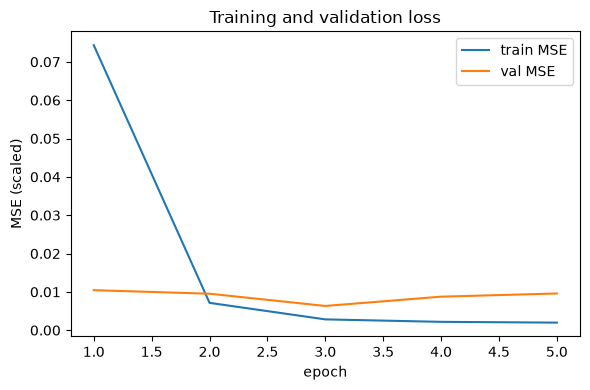

In [8]:
# To-Do (code): Adam + MSELoss, training and validation loops, print epoch losses
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_one_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(xb)
            total_n += len(xb)
    return total_loss / total_n

history = {'train': [], 'val': []}
best_val, best_state = float('inf'), None
for epoch in range(1, EPOCHS + 1):
    train_loss = run_one_epoch(train_loader, train=True)
    val_loss = run_one_epoch(val_loader, train=False)
    history['train'].append(train_loss)
    history['val'].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch:2d}/{EPOCHS} | train MSE {train_loss:.5f} | val MSE {val_loss:.5f}')

model.load_state_dict(best_state)   # use the best epoch, not necessarily the last one
print('Restored best weights (lowest val MSE):', round(best_val, 5))

plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), history['train'], label='train MSE')
plt.plot(range(1, EPOCHS + 1), history['val'], label='val MSE')
plt.title('Training and validation loss')
plt.xlabel('epoch'); plt.ylabel('MSE (scaled)'); plt.legend(); plt.tight_layout(); plt.show()

# Part 7: Evaluate on the test set

**Task from the brief**
Evaluate with R² on the test set. Undo the scaling first, so the numbers are in dollars. Plot actual vs predicted prices. Save the scaler with joblib and the model with `torch.save`.

**Learning point**
- **R²** (coefficient of determination) measures how much of the real movement the model explains. 1.0 is perfect. 0 means the model is no better than always predicting the average.
- Prices trend up over time, so a model that just copies yesterday's price can already score a high R². That is why I also compare with a **naive baseline**: tomorrow = today's close.

**What this cell does:** runs the model on the test windows, turns the scaled predictions back into dollars with the target scaler's `inverse_transform`, and computes R², MAE (average size of the error in dollars), and the naive baseline.

In [9]:
# To-Do (code): test-set predictions, inverse-scale to dollars, R2
def predict(loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(preds)

pred_scaled = predict(test_loader)
pred_price = target_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
actual_price = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

r2 = r2_score(actual_price, pred_price)
mae = np.mean(np.abs(actual_price - pred_price))
print(f'Test R²  (LSTM):           {r2:.4f}')
print(f'Test MAE (LSTM):           ${mae:.2f}')

# Naive baseline (my addition): predict tomorrow's close = today's close
naive_r2 = r2_score(actual_price, test_today_close)
naive_mae = np.mean(np.abs(actual_price - test_today_close))
print(f'Test R²  (naive baseline): {naive_r2:.4f}')
print(f'Test MAE (naive baseline): ${naive_mae:.2f}')

# Diagnostic: how many test targets are outside the range the scaler saw in training?
print(f'Test targets above the training max (scaled > 1): {np.mean(y_test > 1):.1%}')

Test R²  (LSTM):           0.0888
Test MAE (LSTM):           $36.16
Test R²  (naive baseline): 0.9895
Test MAE (naive baseline): $3.17
Test targets above the training max (scaled > 1): 99.6%


**Why the LSTM looks worse here (my reading of the result):** AAPL rose a lot after 2023. Almost every test day closes above the highest price in the training data. MinMax scaling was fit on training data only, so those prices become scaled values above 1. The LSTM learned from values between 0 and 1 and cannot predict far outside that range. The naive baseline does not have this problem, because it copies today's price, which is already in range. This is a real limit of this setup and not a bug. Ways to deal with it are listed in the next steps.

**What this cell does:** plots the real closing price against the LSTM prediction for every day in the test period.

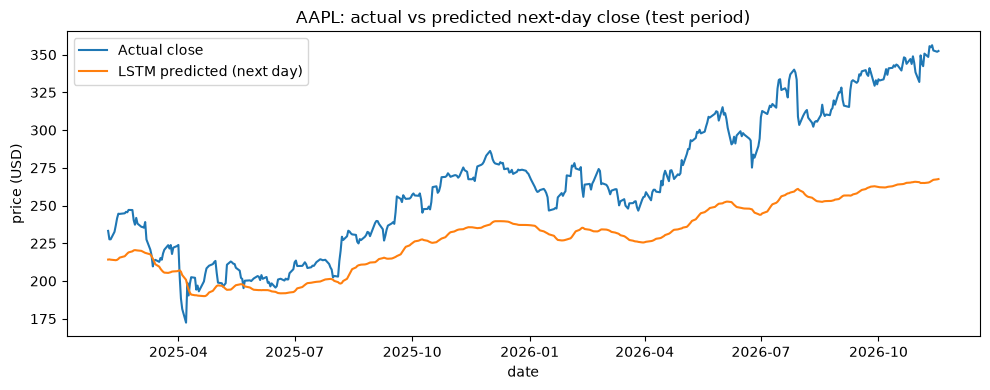

In [10]:
# PREFILLED-style plot: actual vs predicted on the test period
plt.figure(figsize=(10, 4))
plt.plot(d_test, actual_price, label='Actual close')
plt.plot(d_test, pred_price, label='LSTM predicted (next day)')
plt.title(f'{TICKER}: actual vs predicted next-day close (test period)')
plt.xlabel('date'); plt.ylabel('price (USD)'); plt.legend(); plt.tight_layout(); plt.show()

**What this cell does:** saves the scalers with **joblib** to `scaler.pkl`, and saves the model weights with **`torch.save`** to `lstm_stock.pt`. To use them later, load the scalers with `joblib.load` and the model with `model.load_state_dict(torch.load(...))`.

In [11]:
# Save the scalers (joblib) and the trained model weights (torch.save)
joblib.dump({'feature_scaler': feature_scaler, 'target_scaler': target_scaler}, 'scaler.pkl')
torch.save(model.state_dict(), 'lstm_stock.pt')
print('Saved scaler.pkl (joblib) and lstm_stock.pt (torch.save)')

Saved scaler.pkl (joblib) and lstm_stock.pt (torch.save)


**To-Do (written):** In plain words, what does R² mean? What does your number tell you?

**My answer:** R² tells me how much of the up-and-down movement of the real price the model explains. My test R² is **0.0888**. A simple baseline that predicts tomorrow = today gets R² **0.9895**, and its MAE is $3.17 versus $36.16 for the LSTM. So in my run the LSTM did **not** beat the naive baseline. I think the main reason is the price range: about 99.6% of the test days close above the highest training price, so the model has to predict values it never saw during training. I did not tune the model to hide this, because the brief asks for MinMax scaling fitted on train only.

## Next steps (optional)
- **Predict the daily change instead of the price** (for example, the percentage change from today to tomorrow). The change stays in a similar range over time, so the scaler does not run out of range. Convert back to a price by adding today's close.
- Try a longer or shorter lookback (for example 30 or 120 days) and compare the test MAE.
- Add more features, such as High and Low, or moving averages, and check whether the validation loss improves.
- Run on a Colab GPU with `EPOCHS = 20` and compare the curves.